# JogjaPulse — Human Mobility di DIY (Des 2021 – Apr 2022)
**Group Project Rekayasa Data · Topik: Human Mobility**

> *Dari tempat tinggal ke tempat beraktivitas — siapa mengalir ke mana di Daerah Istimewa Yogyakarta?*

| Kode | Pertanyaan | Data |
|---|---|---|
| **Q1** | Kapanewon mana yang menjadi pusat aktivitas siang hari, dan mana yang lebih bersifat permukiman? | `presence_kapanewon_hourly` + populasi |
| **Q2** | Dari mana pengunjung Kota Yogyakarta berasal, dan seberapa kuat tarikannya? | `od_home_visits` + `od_origin_homes` + populasi |
| **Q3** | Bagaimana pola kehadiran saat libur akhir tahun dibanding hari biasa? | `presence_kapanewon_hourly` (+ `presence_cell500m_daily`) |
| **Q4** | Apakah pola tersebut konsisten dengan sumber independen? | hasil Q1/Q3 + Google Mobility (DIY) |

**Sumber data** (10 CSV di folder `data/`)
1. Widyawan, Pratama, A. R., Ariansyah, A., Farda, N. M., Pramana, S., & Miller, O. (2026). *JogjaPulse: An Aggregated Spatio-Temporal Mobility Dataset for Yogyakarta, Indonesia* [Dataset]. Universitas Gadjah Mada. https://doi.org/10.5281/zenodo.23157460 (CC BY 4.0; agregat perangkat seluler, k-anonymity k = 5).
2. Google LLC. *Google COVID-19 Community Mobility Reports*. https://www.google.com/covid19/mobility/ (provinsi DIY, perubahan % dari baseline; 2021 & 2022).

**Alur:** `1 Setup → 2 Muat & periksa → 3 Bersihkan & samakan kunci → 4 Normalisasi → 5 Analisis → 6 Visualisasi → 7 Kualitas & keterbatasan → 8 Ekspor`

## Tahap 1 — Setup
Parameter analisis dikumpulkan di satu sel agar semua anggota kelompok memakai definisi yang sama.

In [ ]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")

DATA_DIR = os.environ.get("JP_DATA_DIR", "data")
OUT_DIR  = os.environ.get("JP_OUT_DIR", "outputs")
for d in (DATA_DIR, f"{OUT_DIR}/figures", f"{OUT_DIR}/tables"):
    os.makedirs(d, exist_ok=True)

# Parameter analisis
WINDOW_MAIN = ("2021-12-01", "2022-02-28")   # periode andal (sebelum degradasi data Mar-Apr)
DAY_HOURS   = list(range(8, 18))             # siang 08:00-17:59 WIB
NIGHT_HOURS = list(range(0, 6))              # malam 00:00-05:59 WIB (sama dengan validasi README)
MIN_COV     = 0.60                           # ambang cakupan slot terpublikasi
HOLIDAY     = ("2021-12-24", "2021-12-31")   # periode libur Natal-Tahun Baru (pilihan analisis; 24 Des bukan cuti bersama)
BASELINE    = ("2021-12-01", "2021-12-23")   # hari biasa pembanding (rezim sampel yang sama)
FOCUS_KAB   = "YOGYAKARTA"                   # tujuan OD yang difokuskan di Q2

# Jendela Q4 per rezim sampel (patahan sampel 1 Jan & 16 Feb 2022)
Q4_WINDOWS = {
    "Des 2021 (rezim 1)":              ("2021-12-01", "2021-12-31"),
    "1 Jan-15 Feb 2022 (rezim 2)":     ("2022-01-01", "2022-02-15"),
    "Des 2021-15 Feb 2022 (gabungan)": ("2021-12-01", "2022-02-15"),
}

# Anotasi grafik (tanggal sudah diverifikasi: SKB 3 Menteri; Inmendagri 9/2022)
EVENTS = {
    "2021-12-25": "Natal",
    "2022-01-01": "Tahun Baru\n(+ patahan sampel)",
    "2022-02-01": "Imlek",
    "2022-02-08": "PPKM L3 DIY\nmulai",
    "2022-02-16": "patahan\nsampel",
}

# Gaya grafik
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
KAB_COLORS = dict(zip(["SLEMAN", "BANTUL", "YOGYAKARTA", "GUNUNGKIDUL", "KULON PROGO"], CAT))
KAB_ABBR   = {"SLEMAN": "SLM", "BANTUL": "BTL", "YOGYAKARTA": "YK", "GUNUNGKIDUL": "GK", "KULON PROGO": "KP"}
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#9ec5f4", "#5598e7", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div_bluered", ["#256abf", "#f0efec", "#e34948"])

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.titlecolor": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10, "font.size": 10, "legend.frameon": False, "figure.dpi": 110,
})

def savefig(name):
    """Simpan grafik sebagai PNG lalu tampilkan."""
    plt.savefig(f"{OUT_DIR}/figures/{name}.png", dpi=170, bbox_inches="tight")
    plt.show()

def bh_fdr(p):
    """Koreksi Benjamini-Hochberg (FDR)."""
    p = np.asarray(p, float); n = len(p); order = np.argsort(p)
    q = np.minimum.accumulate((p[order] * n / np.arange(1, n + 1))[::-1])[::-1]
    out = np.empty(n); out[order] = np.minimum(q, 1); return out

## Tahap 2 — Muat dan periksa data
Membaca 10 CSV dari `data/` dan mencocokkan jumlah baris dengan README sebelum analisis.

In [ ]:
def get_file(name, source="zenodo"):
    path = os.path.join(DATA_DIR, name)
    if not os.path.exists(path):
        asal = "https://doi.org/10.5281/zenodo.23157460" if source == "zenodo" else "https://www.google.com/covid19/mobility/"
        raise FileNotFoundError(f"'{name}' tidak ada di '{DATA_DIR}/'. Unduh dari {asal}.")
    return path

hourly   = pd.read_csv(get_file("presence_kapanewon_hourly.csv"))
cell     = pd.read_csv(get_file("presence_cell500m_daily.csv"))
od       = pd.read_csv(get_file("od_home_visits_kapanewon_monthly.csv"))
od_orig  = pd.read_csv(get_file("od_origin_homes_monthly.csv"))
pop      = pd.read_csv(get_file("home_maids_vs_population_kapanewon.csv"))
valid    = pd.read_csv(get_file("validation_night_presence_kapanewon.csv"))
tier1    = pd.read_csv(get_file("tier1_summary.csv"))
od_sum   = pd.read_csv(get_file("od_summary.csv"))
g_raw    = pd.concat([pd.read_csv(get_file(f"{y}_ID_Region_Mobility_Report.csv", "google"), low_memory=False)
                      for y in (2021, 2022)], ignore_index=True)

expected = {"hourly": (hourly, 230418), "cell500m": (cell, 183548), "od": (od, 9894),
            "od_origin": (od_orig, 390), "populasi": (pop, 78), "validasi": (valid, 156),
            "tier1_summary": (tier1, 2), "od_summary": (od_sum, 1)}
chk = pd.DataFrame([{"file": k, "baris_aktual": len(v[0]), "baris_README": v[1], "kolom": v[0].shape[1],
                     "sel_kosong": int(v[0].isna().sum().sum()),
                     "cocok": "OK" if len(v[0]) == v[1] else "BEDA"} for k, v in expected.items()])
display(chk)
assert (chk.cocok == "OK").all(), "Jumlah baris tidak sesuai README"
print(f"hourly: {hourly.date.min()} -> {hourly.date.max()} ({hourly.date.nunique()} hari) | OD: {sorted(od.month.unique())}")

,file,baris_aktual,baris_README,kolom,sel_kosong,cocok
0,hourly,230418,230418,8,0,OK
1,cell500m,183548,183548,7,0,OK
2,od,9894,9894,11,0,OK
3,od_origin,390,390,8,0,OK
4,populasi,78,78,5,0,OK
5,validasi,156,156,7,0,OK
6,tier1_summary,2,2,8,0,OK
7,od_summary,1,1,7,0,OK


hourly: 2021-12-01 -> 2022-04-30 (151 hari) | OD: ['2021-12', '2022-01', '2022-02', '2022-03', '2022-04']


## Tahap 3 — Bersihkan dan samakan kunci
- Kunci gabungan = `kab_kota|kapanewon` (nama `JETIS` ada di Bantul dan Kota Yogyakarta).
- Baris hilang berarti "<5 perangkat" (k = 5), **bukan nol**; tidak diisi 0.
- OD Mar–Apr 2022 berkualitas rendah (`reduced_quality`) dan dikeluarkan.

In [ ]:
# 3a. Kunci gabungan & kalender
hourly["date"] = pd.to_datetime(hourly["date"])
hourly["key"]  = hourly.kab_kota + "|" + hourly.kapanewon
hourly["dow"]  = hourly.date.dt.dayofweek
hourly["is_weekend"] = hourly.dow >= 5
cell["date"] = pd.to_datetime(cell["date"])

pop["key"] = pop.KAB_KOTA + "|" + pop.KEC_KAPN
meta = (hourly[["key", "kab_kota", "kapanewon", "kapanewon_code"]].drop_duplicates()
        .merge(pop[["key", "n_users", "pop_actual"]], on="key", how="left"))
meta["label"] = meta.kapanewon.str.title() + " (" + meta.kab_kota.map(KAB_ABBR) + ")"
assert meta.pop_actual.notna().all(), "Ada kapanewon tanpa data populasi"
assert meta.key.is_unique and len(meta) == 78
label_of = meta.set_index("key").label

# 3b. OD: buang bulan kualitas rendah, tempel penyebut (perangkat asal)
od["key_o"] = od.origin_kab_kota + "|" + od.origin_kapanewon
od["key_d"] = od.dest_kab_kota + "|" + od.dest_kapanewon
od_ok = od[~od.reduced_quality].copy()
den = od_orig[["month", "origin_code", "n_homed_maids", "n_homed_maids_daytime"]]
od_ok = od_ok.merge(den, on=["month", "origin_code"], how="left")
assert od_ok.n_homed_maids_daytime.notna().all(), "Ada pasangan OD tanpa penyebut"
od_ok["share"] = od_ok.n_maids / od_ok.n_homed_maids_daytime

# 3c. Google Mobility: provinsi DIY, rentang yang sama
g = g_raw[(g_raw.sub_region_1 == "Special Region of Yogyakarta") & g_raw.sub_region_2.isna()].copy()
g["date"] = pd.to_datetime(g["date"])
g = g.set_index("date").sort_index().loc["2021-12-01":"2022-04-30"]
g.columns = [c.replace("_percent_change_from_baseline", "") for c in g.columns]
G_COLS = ["retail_and_recreation", "grocery_and_pharmacy", "parks", "transit_stations", "workplaces", "residential"]
g = g[G_COLS]

print(f"Kapanewon: {len(meta)} | OD dipakai: {od_ok.month.unique().tolist()} ({len(od_ok)} baris) | Google DIY: {g.shape[0]} hari, kosong {int(g.isna().sum().sum())}")
display(g.describe().round(1).T)

Kapanewon: 78 | OD dipakai: ['2021-12', '2022-01', '2022-02'] (7872 baris) | Google DIY: 151 hari, kosong 0


,count,mean,std,min,25%,50%,75%,max
retail_and_recreation,151.0,4.4,6.9,-21.0,0.0,5.0,9.0,21.0
grocery_and_pharmacy,151.0,15.1,7.4,-3.0,10.5,14.0,19.5,41.0
parks,151.0,10.1,17.7,-37.0,1.0,7.0,19.0,82.0
transit_stations,151.0,-23.1,9.1,-43.0,-29.0,-23.0,-17.0,1.0
workplaces,151.0,-4.1,11.8,-54.0,-10.0,-1.0,3.0,17.0
residential,151.0,11.3,4.6,5.0,7.0,11.0,15.0,24.0


## Tahap 4 — Normalisasi
Jumlah perangkat terpantau turun dari ±87 ribu/hari (Des 2021) ke ±9 ribu (Apr 2022), dengan patahan pada 1 Jan dan 16 Feb 2022 (perubahan komposisi sampel, bukan perilaku warga). Karena itu yang dibandingkan adalah proporsi dan pola, bukan hitungan mentah:

| Besaran | Normalisasi |
|---|---|
| Pola harian (Q1) | indeks terhadap rata-rata 24 jam kapanewon itu sendiri |
| Rasio siang/malam (Q1, Q4) | rata-rata siang ÷ rata-rata malam; skala sampel hilang, tetapi level masih bisa bergeser antar-rezim, sehingga dibandingkan dalam rezim yang sama |
| Kehadiran antar-hari (Q3) | pangsa kapanewon terhadap total *device-hours* se-DIY hari itu |
| OD (Q2) | `n_maids ÷ n_homed_maids_daytime` (pangsa perangkat asal) |

> Total perangkat unik se-DIY tidak tersedia dan `n_maids` tidak boleh dijumlahkan, sehingga penyebutnya adalah **penyebut pendekatan** (jumlah `n_maids` baris terpublikasi, satuan *device-hours*, bukan orang). Dicatat di Tahap 7.

In [ ]:
reg_hour = hourly.groupby(["date", "hour"]).n_maids.sum().unstack("hour")
daily = pd.DataFrame({
    "device_hours": reg_hour.sum(axis=1),
    "day_dh":   reg_hour[DAY_HOURS].sum(axis=1),
    "night_dh": reg_hour[NIGHT_HOURS].sum(axis=1),
})
daily["day_night_ratio"] = daily.day_dh / daily.night_dh
daily["pings"] = hourly.groupby("date").n_pings.sum()

dh = hourly.groupby(["key", "date"]).n_maids.sum().unstack("key")
dh_share = dh.div(dh.sum(axis=1), axis=0)
print("Penjumlahan pangsa per hari = 1 ->", np.allclose(dh_share.sum(axis=1), 1))

Penjumlahan pangsa per hari = 1 -> True


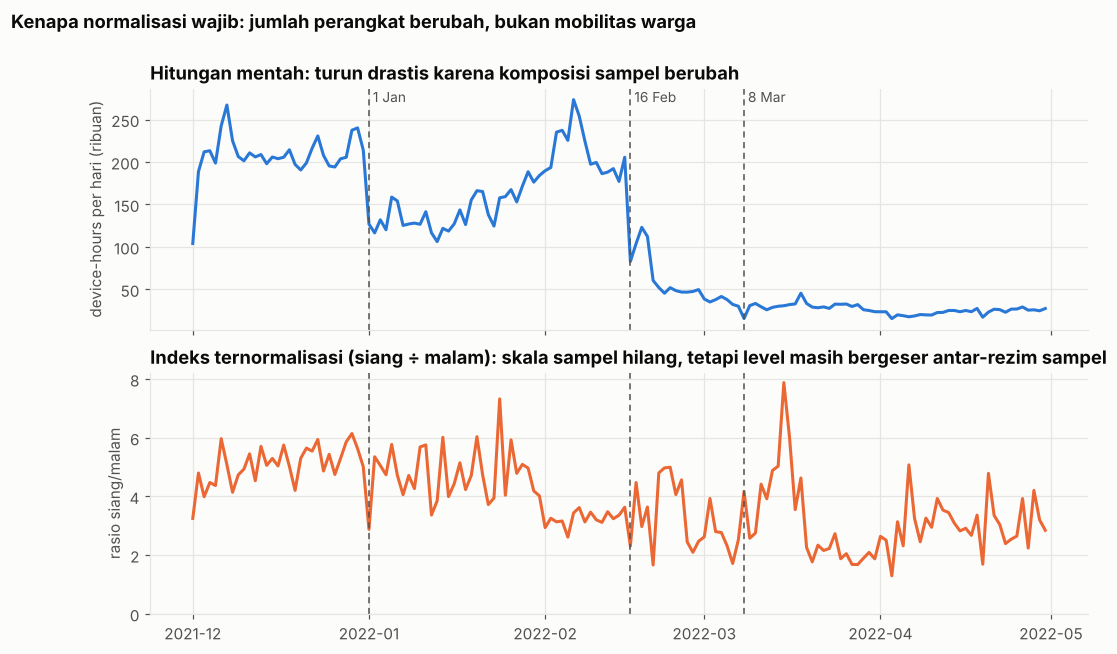

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6.2), sharex=True, gridspec_kw={"hspace": 0.18})
ax[0].plot(daily.index, daily.device_hours / 1e3, color=CAT[0], lw=2)
ax[0].set_ylabel("device-hours per hari (ribuan)")
ax[0].set_title("Hitungan mentah: turun drastis karena komposisi sampel berubah")
ax[1].plot(daily.index, daily.day_night_ratio, color=CAT[1], lw=2)
ax[1].set_ylabel("rasio siang/malam")
ax[1].set_title("Indeks ternormalisasi (siang ÷ malam): skala sampel hilang, tetapi level masih bergeser antar-rezim sampel")
for d, lbl in {"2022-01-01": "1 Jan", "2022-02-16": "16 Feb", "2022-03-08": "8 Mar"}.items():
    for a in ax:
        a.axvline(pd.Timestamp(d), color=INK2, lw=1, ls=(0, (4, 3)))
    ax[0].text(pd.Timestamp(d), ax[0].get_ylim()[1], " " + lbl, va="top", fontsize=9, color=INK2)
ax[1].set_ylim(0, None)
plt.suptitle("Kenapa normalisasi wajib: jumlah perangkat berubah, bukan mobilitas warga", x=0.01, ha="left", fontweight="bold", y=0.995)
savefig("01_drift_sampel_vs_indeks")

## Tahap 5 — Analisis per pertanyaan (Q1–Q4)
Periode utama Des 2021 – Feb 2022, memakai besaran ternormalisasi dari Tahap 4. Visualisasinya ada di Tahap 6 (5.1 → 6.1, dst.).

### 5.1 — Q1: Pusat aktivitas siang vs permukiman
Rasio siang/malam = rata-rata perangkat jam 08–17 ÷ jam 00–05 (>1 berarti lebih hidup di siang hari). Bentuk pola 24 jam lalu dikelompokkan dengan k-means. Hanya kapanewon dengan cakupan slot ≥ `MIN_COV` yang dihitung, karena baris yang di-suppress membuat rata-rata terlalu tinggi.

In [ ]:
W0, W1 = WINDOW_MAIN
hw = hourly[(hourly.date >= W0) & (hourly.date <= W1)]
n_days = hw.date.nunique()

cov_all   = hw.groupby("key").size() / (n_days * 24)
cov_night = hw[hw.hour.isin(NIGHT_HOURS)].groupby("key").size() / (n_days * len(NIGHT_HOURS))
day_mean   = hw[hw.hour.isin(DAY_HOURS)].groupby("key").n_maids.mean()
night_mean = hw[hw.hour.isin(NIGHT_HOURS)].groupby("key").n_maids.mean()

q1 = meta.set_index("key")[["kab_kota", "kapanewon", "label", "pop_actual"]].copy()
q1["day_mean"], q1["night_mean"] = day_mean, night_mean
q1["ratio"] = q1.day_mean / q1.night_mean
q1["cov_all"], q1["cov_night"] = cov_all, cov_night
q1["eligible"] = (q1.cov_all >= MIN_COV) & (q1.cov_night >= MIN_COV)
print(f"Memenuhi ambang cakupan {MIN_COV:.0%}: {q1.eligible.sum()} dari {len(q1)} | dikeluarkan: " + ", ".join(q1[~q1.eligible].label))
q1_el = q1[q1.eligible].sort_values("ratio", ascending=False)
cols1 = ["label", "day_mean", "night_mean", "ratio", "cov_night"]
display(q1_el[cols1].head(10).round(2))
display(q1_el[cols1].tail(6).round(2))

Memenuhi ambang cakupan 60%: 64 dari 78 | dikeluarkan: Girimulyo (KP), Patuk (GK), Semin (GK), Gedongtengen (YK), Ngampilan (YK), Panggang (GK), Ngawen (GK), Paliyan (GK), Saptosari (GK), Girisubo (GK), Purwosari (GK), Rongkop (GK), Tanjungsari (GK), Tepus (GK)


,label,day_mean,night_mean,ratio,cov_night
key,,,,,
GUNUNGKIDUL|PLAYEN,Playen (GK),65.65,18.25,3.60,0.94
KULON PROGO|SAMIGALUH,Samigaluh (KP),51.88,15.32,3.39,0.89
GUNUNGKIDUL|WONOSARI,Wonosari (GK),172.91,52.32,3.30,0.99
KULON PROGO|NANGGULAN,Nanggulan (KP),64.62,19.89,3.25,0.97
KULON PROGO|KOKAP,Kokap (KP),77.98,24.03,3.25,0.98
BANTUL|PANDAK,Pandak (BTL),114.71,35.75,3.21,1.00
KULON PROGO|SENTOLO,Sentolo (KP),78.48,24.83,3.16,0.99
SLEMAN|PRAMBANAN,Prambanan (SLM),95.18,30.37,3.13,0.99
GUNUNGKIDUL|NGLIPAR,Nglipar (GK),30.20,9.68,3.12,0.73


,label,day_mean,night_mean,ratio,cov_night
key,,,,,
BANTUL|DLINGO,Dlingo (BTL),19.57,9.19,2.13,0.64
KULON PROGO|PANJATAN,Panjatan (KP),20.83,9.97,2.09,0.67
YOGYAKARTA|KRATON,Kraton (YK),55.22,27.02,2.04,0.97
SLEMAN|SLEMAN,Sleman (SLM),192.46,96.60,1.99,1.00
YOGYAKARTA|MANTRIJERON,Mantrijeron (YK),36.24,18.29,1.98,0.79
YOGYAKARTA|GONDOMANAN,Gondomanan (YK),102.56,103.67,0.99,1.00


In [ ]:
OUTLIERS = ["YOGYAKARTA|GONDOMANAN"]   # profil datar 24 jam, >2 perangkat per penduduk: tidak di-klaster (lihat 7.5d)
K_CLUSTERS = 3

wk = hw[~hw.is_weekend & hw.key.isin(q1_el.index)]
prof = wk.groupby(["key", "hour"]).n_maids.mean().unstack("hour")
prof = prof.reindex(columns=range(24)).interpolate(axis=1, limit_direction="both")
prof_idx = prof.div(prof.mean(axis=1), axis=0)
core = prof_idx.drop(index=[k for k in OUTLIERS if k in prof_idx.index])

sil = {k: silhouette_score(core, KMeans(k, n_init=10, random_state=42).fit_predict(core)) for k in range(2, 6)}
print("Silhouette per k:", {k: round(v, 3) for k, v in sil.items()}, "-> dipakai k =", K_CLUSTERS)
km = KMeans(K_CLUSTERS, n_init=10, random_state=42).fit(core)
core_lab = pd.Series(km.labels_, index=core.index)

# Nama klaster dari bentuk pola: jam puncak + kedalaman dasar malam
desc = {c: {"peak_hour": int(core[core_lab == c].mean().idxmax()),
            "amplitudo": float(core[core_lab == c].mean().max() - core[core_lab == c].mean().min()),
            "dasar": float(core[core_lab == c].mean().min())} for c in range(K_CLUSTERS)}
order = sorted(desc, key=lambda c: (desc[c]["peak_hour"], -desc[c]["amplitudo"]))
name_map = {c: f"K{i + 1} - puncak jam {desc[c]['peak_hour']:02d}, dasar malam {desc[c]['dasar']:.2f}" for i, c in enumerate(order)}
q1_el = q1_el.copy()
q1_el["cluster"] = [name_map[core_lab[k]] if k in core_lab.index else "Outlier - profil datar" for k in q1_el.index]

print("Rasio siang/malam (persentil 10 / 50 / 90):", q1_el.ratio.quantile([.1, .5, .9]).round(2).tolist())
display(q1_el.groupby("cluster").agg(n=("ratio", "size"), rasio_rata2=("ratio", "mean")).round(2))
for c, grp in q1_el.groupby("cluster"):
    print(f"\n[{c}] ({len(grp)}):", ", ".join(grp.sort_values("ratio", ascending=False).label))

Silhouette per k: {2: 0.246, 3: 0.253, 4: 0.211, 5: 0.197} -> dipakai k = 3
Rasio siang/malam (persentil 10 / 50 / 90): [2.14, 2.63, 3.15]


,n,rasio_rata2
cluster,,
"K1 - puncak jam 12, dasar malam 0.29",18,3.08
"K2 - puncak jam 12, dasar malam 0.41",15,2.37
"K3 - puncak jam 19, dasar malam 0.35",30,2.55
Outlier - profil datar,1,0.99



[K1 - puncak jam 12, dasar malam 0.29] (18): Playen (GK), Samigaluh (KP), Wonosari (GK), Nanggulan (KP), Kokap (KP), Pandak (BTL), Sentolo (KP), Prambanan (SLM), Nglipar (GK), Ponjong (GK), Turi (SLM), Temon (KP), Seyegan (SLM), Pengasih (KP), Gedangsari (GK), Wates (KP), Karangmojo (GK), Pakem (SLM)

[K2 - puncak jam 12, dasar malam 0.41] (15): Danurejan (YK), Gamping (SLM), Gondokusuman (YK), Jetis (YK), Pakualaman (YK), Mlati (SLM), Mergangsan (YK), Bantul (BTL), Tegalrejo (YK), Umbulharjo (YK), Depok (SLM), Wirobrajan (YK), Kraton (YK), Sleman (SLM), Mantrijeron (YK)

[K3 - puncak jam 19, dasar malam 0.35] (30): Kretek (BTL), Cangkringan (SLM), Imogiri (BTL), Bambanglipuro (BTL), Jetis (BTL), Semanu (GK), Pleret (BTL), Minggir (SLM), Lendah (KP), Srandakan (BTL), Godean (SLM), Galur (KP), Pundong (BTL), Banguntapan (BTL), Sedayu (BTL), Moyudan (SLM), Kalasan (SLM), Sanden (BTL), Berbah (SLM), Tempel (SLM), Kotagede (YK), Piyungan (BTL), Sewon (BTL), Ngaglik (SLM), Kasihan (BTL), N

**Catatan Q1:** rasio hampir semua kapanewon berkisar 2–3 dan peringkatnya hanya cukup stabil (Tahap 7.5a), sehingga selisih peringkat berdekatan jangan ditafsirkan. Klaster (dasar malam lebih dangkal = lebih hidup di malam hari) lemah (silhouette ≈ 0,25): anggap sebagai kontinum. Gondomanan dikeluarkan sebagai outlier (Tahap 7.5d).

### 5.2 — Q2: Dari mana pengunjung Kota Yogyakarta berasal?
- **Pangsa kunjungan** `i → j` = `n_maids(i→j) ÷ n_homed_maids_daytime(i)`.
- **Volume masuk** ke `j` = jumlah `n_maids` dari semua asal `i ≠ j`. Boleh dijumlahkan antar-asal (satu perangkat = satu rumah bulanan), tidak boleh antar-tujuan.
- Periode Des 2021 – Feb 2022. Pasangan <5 perangkat tidak dipublikasikan, sehingga angka adalah batas bawah.

In [ ]:
print("Aliran antar-zona yang terpublikasi (od_summary):", od_sum.inter_zonal_flow_kept_pct.iloc[0], "%")
inter = od_ok[od_ok.origin_code != od_ok.dest_code].copy()

# Volume masuk per tujuan (rata-rata bulanan) + indeks per 1.000 penduduk tujuan
inflow = (inter.groupby(["dest_kab_kota", "dest_kapanewon", "month"]).n_maids.sum().groupby(level=[0, 1]).mean()
          .rename("inflow_mean").reset_index())
inflow["key"] = inflow.dest_kab_kota + "|" + inflow.dest_kapanewon
inflow = inflow.merge(meta[["key", "label", "pop_actual"]], on="key")
inflow["inflow_per_1000"] = inflow.inflow_mean / inflow.pop_actual * 1000
inflow = inflow.sort_values("inflow_mean", ascending=False)
display(inflow[["label", "inflow_mean", "pop_actual", "inflow_per_1000"]].head(10).round(1))

# Fokus: tujuan di Kota Yogyakarta
focus = inter[inter.dest_kab_kota == FOCUS_KAB]
top_dest_label = inflow[inflow.dest_kab_kota == FOCUS_KAB].iloc[0].label
top_dest_key = inflow[inflow.dest_kab_kota == FOCUS_KAB].iloc[0].key
print("Tujuan teratas di", FOCUS_KAB.title(), ":", top_dest_label)

# Komposisi asal per kabupaten/kota (aditif antar-asal)
comp = (focus.groupby(["dest_kapanewon", "origin_kab_kota", "month"]).n_maids.sum()
        .groupby(level=[0, 1]).mean().unstack("origin_kab_kota").fillna(0))
comp_pct = comp.div(comp.sum(axis=1), axis=0) * 100
comp_pct = comp_pct.loc[comp.sum(axis=1).sort_values().index]
display(comp_pct.round(1))

# Matriks pangsa kunjungan: asal (baris) x tujuan fokus (kolom)
mat = focus.groupby(["key_o", "dest_kapanewon"]).share.mean().unstack("dest_kapanewon")
mat.index = [label_of[k] for k in mat.index]
print("Matriks asal x tujuan:", mat.shape, "| sel kosong (<5 perangkat):", f"{mat.isna().mean().mean():.0%}")

Aliran antar-zona yang terpublikasi (od_summary): 95.3 %


,label,inflow_mean,pop_actual,inflow_per_1000
49,Depok (SLM),9176.3,130980.0,70.1
1,Banguntapan (BTL),6102.0,125210.0,48.7
56,Ngaglik (SLM),5937.7,105960.0,56.0
50,Gamping (SLM),5479.0,103810.0,52.8
76,Umbulharjo (YK),4935.7,68450.0,72.1
66,Gondokusuman (YK),4933.7,37070.0,133.1
54,Mlati (SLM),4902.3,100500.0,48.8
6,Kasihan (BTL),4646.3,115250.0,40.3
58,Pakem (SLM),4254.0,37580.0,113.2
57,Ngemplak (SLM),3870.7,68440.0,56.6


Tujuan teratas di Yogyakarta : Umbulharjo (YK)


origin_kab_kota,BANTUL,GUNUNGKIDUL,KULON PROGO,SLEMAN,YOGYAKARTA
dest_kapanewon,,,,,
NGAMPILAN,28.9,0.8,2.6,37.4,30.3
WIROBRAJAN,38.6,0.7,2.1,36.9,21.7
GEDONGTENGEN,22.8,1.5,1.6,46.4,27.7
MANTRIJERON,45.3,0.6,2.3,28.1,23.7
KRATON,35.2,1.2,1.5,28.4,33.7
PAKUALAMAN,15.0,0.3,0.4,19.7,64.6
TEGALREJO,19.6,3.0,5.6,55.6,16.2
DANUREJAN,17.9,0.6,1.3,32.9,47.4
MERGANGSAN,26.3,0.8,1.7,22.3,49.0


Matriks asal x tujuan: (73, 14) | sel kosong (<5 perangkat): 26%


### 5.3 — Q3: Libur akhir tahun vs hari biasa
Membandingkan pangsa *device-hours* tiap kapanewon pada 24–31 Des 2021 dengan 1–23 Des 2021. Hanya Desember agar kedua periode berada dalam rezim sampel yang sama (patahan 1 Jan). Ukuran utama adalah selisih **median** pangsa (kebal lonjakan 1–3 hari), diuji dengan Mann–Whitney + koreksi FDR. Hasil bersifat eksploratif.

In [ ]:
base_idx = dh_share.loc[BASELINE[0]:BASELINE[1]].index
hol_idx  = dh_share.loc[HOLIDAY[0]:HOLIDAY[1]].index
wkend = lambda idx: (idx.dayofweek >= 5).mean()
print(f"Hari libur: {len(hol_idx)} (akhir pekan {wkend(hol_idx):.0%}) | hari pembanding: {len(base_idx)} (akhir pekan {wkend(base_idx):.0%})")

dec = hourly[(hourly.date >= "2021-12-01") & (hourly.date <= "2021-12-31")]
cov_dec = dec.groupby("key").size() / (31 * 24)
elig3 = cov_dec[cov_dec >= MIN_COV].index

rows = []
for k in elig3:
    b, h_ = dh_share.loc[base_idx, k], dh_share.loc[hol_idx, k]
    allv = pd.concat([b, h_])
    p = stats.mannwhitneyu(h_, b, alternative="two-sided").pvalue
    rows.append({"key": k, "base_pct": b.median() * 100, "hol_pct": h_.median() * 100,
                 "base_mean_pct": b.mean() * 100, "hol_mean_pct": h_.mean() * 100, "p": p,
                 "spike_ratio": allv.max() / allv.median(), "spike_date": allv.idxmax().date()})
q3 = pd.DataFrame(rows).set_index("key")
q3["delta_pp"] = q3.hol_pct - q3.base_pct                  # selisih median (poin persentase)
q3["delta_mean_pp"] = q3.hol_mean_pct - q3.base_mean_pct   # pembanding
q3["rel_change_pct"] = (q3.hol_pct / q3.base_pct - 1) * 100
q3["q_fdr"] = bh_fdr(q3.p.values)
q3 = q3.join(meta.set_index("key")[["label", "kab_kota"]]).sort_values("delta_pp")
print("Kapanewon dianalisis:", len(q3), "| signifikan (q<0.05):", int((q3.q_fdr < 0.05).sum()))
cols3 = ["label", "base_pct", "hol_pct", "delta_pp", "delta_mean_pp", "rel_change_pct", "q_fdr"]
print("Turun terbesar (selisih median):"); display(q3[cols3].head(6).round(3))
print("Naik terbesar (selisih median):");  display(q3[cols3].tail(6).round(3))
print("Lonjakan harian paling ekstrem (maks / median):")
display(q3.sort_values("spike_ratio", ascending=False)[["label", "spike_ratio", "spike_date"]].head(5).round(2))

Hari libur: 8 (akhir pekan 25%) | hari pembanding: 23 (akhir pekan 26%)


Kapanewon dianalisis: 76 | signifikan (q<0.05): 3
Turun terbesar (selisih median):


,label,base_pct,hol_pct,delta_pp,delta_mean_pp,rel_change_pct,q_fdr
key,,,,,,,
SLEMAN|PAKEM,Pakem (SLM),4.063,3.047,-1.016,-1.760,-25.013,0.240
SLEMAN|GAMPING,Gamping (SLM),7.494,6.492,-1.002,-1.124,-13.370,0.297
SLEMAN|SEYEGAN,Seyegan (SLM),5.260,4.796,-0.465,-1.127,-8.830,0.169
BANTUL|KRETEK,Kretek (BTL),0.939,0.727,-0.212,0.045,-22.575,0.545
GUNUNGKIDUL|GEDANGSARI,Gedangsari (GK),0.456,0.304,-0.152,-0.133,-33.318,0.001
SLEMAN|GODEAN,Godean (SLM),2.054,1.918,-0.137,-0.127,-6.645,0.240


Naik terbesar (selisih median):


,label,base_pct,hol_pct,delta_pp,delta_mean_pp,rel_change_pct,q_fdr
key,,,,,,,
SLEMAN|NGAGLIK,Ngaglik (SLM),4.525,4.736,0.211,3.627,4.672,0.346
KULON PROGO|LENDAH,Lendah (KP),0.264,0.530,0.266,0.196,100.884,0.069
BANTUL|BANTUL,Bantul (BTL),1.722,1.989,0.266,0.173,15.457,0.403
YOGYAKARTA|UMBULHARJO,Umbulharjo (YK),2.610,2.949,0.339,0.158,12.970,0.555
BANTUL|SEWON,Sewon (BTL),2.014,2.394,0.381,0.161,18.910,0.408
SLEMAN|NGEMPLAK,Ngemplak (SLM),2.999,3.420,0.420,0.246,14.017,0.521


Lonjakan harian paling ekstrem (maks / median):


,label,spike_ratio,spike_date
key,,,
YOGYAKARTA|GONDOMANAN,Gondomanan (YK),7.50,2021-12-01
YOGYAKARTA|MANTRIJERON,Mantrijeron (YK),4.95,2021-12-01
YOGYAKARTA|GEDONGTENGEN,Gedongtengen (YK),4.93,2021-12-01
SLEMAN|NGAGLIK,Ngaglik (SLM),3.65,2021-12-30
KULON PROGO|GIRIMULYO,Girimulyo (KP),3.53,2021-12-01


In [ ]:
# Peta sel 500 m (opsional). Pangsa sel = n_maids / total n_maids hari itu (pendekatan)
USE_CELL = True
if USE_CELL:
    cell["share"] = cell.n_maids / cell.groupby("date").n_maids.transform("sum")
    cb = cell[(cell.date >= BASELINE[0]) & (cell.date <= BASELINE[1])]
    ch = cell[(cell.date >= HOLIDAY[0]) & (cell.date <= HOLIDAY[1])]
    agg = lambda d: d.groupby("cell_id").agg(mean_share=("share", "mean"), n_days=("share", "size"),
                                               lon=("centroid_lon", "first"), lat=("centroid_lat", "first"))
    cb_, ch_ = agg(cb), agg(ch)
    q3c = cb_.join(ch_, lsuffix="_b", rsuffix="_h", how="inner")
    q3c = q3c[(q3c.n_days_b >= 12) & (q3c.n_days_h >= 5)].copy()   # sel yang cukup sering terpublikasi
    q3c["log2_change"] = np.log2(q3c.mean_share_h / q3c.mean_share_b)
    print("Sel dianalisis:", len(q3c), "dari", cell.cell_id.nunique())
    show = ["lon_b", "lat_b", "mean_share_b", "mean_share_h", "log2_change"]
    print("\nKenaikan pangsa terbesar (log2):"); display(q3c.sort_values("log2_change", ascending=False)[show].head(5).round(5))
    print("Penurunan pangsa terbesar (log2):"); display(q3c.sort_values("log2_change")[show].head(5).round(5))
    print("Cek lokasi di peta:")
    for cid, r in q3c.nlargest(3, "log2_change").iterrows():
        print(f"  {cid}: https://www.google.com/maps?q={r.lat_b},{r.lon_b}")

Sel dianalisis: 1161 dari 5715

Kenaikan pangsa terbesar (log2):


,lon_b,lat_b,mean_share_b,mean_share_h,log2_change
cell_id,,,,,
E865_N18299,110.39020,-7.69158,0.01010,0.04559,2.17461
E854_N18260,110.34006,-7.86789,0.00017,0.00055,1.69569
E860_N18309,110.36760,-7.64632,0.00029,0.00073,1.32270
E813_N18261,110.15412,-7.86303,0.00014,0.00034,1.28210
E848_N18282,110.31301,-7.76835,0.00006,0.00015,1.26194


Penurunan pangsa terbesar (log2):


,lon_b,lat_b,mean_share_b,mean_share_h,log2_change
cell_id,,,,,
E869_N18273,110.40817,-7.80920,0.00052,0.00010,-2.44576
E850_N18268,110.32197,-7.83168,0.00081,0.00017,-2.27501
E819_N18281,110.18150,-7.77264,0.00158,0.00033,-2.26769
E865_N18255,110.38991,-7.89058,0.00311,0.00065,-2.26049
E859_N18271,110.36281,-7.81818,0.00029,0.00007,-2.07532


Cek lokasi di peta:
  E865_N18299: https://www.google.com/maps?q=-7.691583,110.390202
  E854_N18260: https://www.google.com/maps?q=-7.867887,110.340057
  E860_N18309: https://www.google.com/maps?q=-7.646324,110.367601


**Catatan Q3:** hanya 3 dari 76 kapanewon signifikan setelah FDR dengan efek kecil (≤ 0,2 poin); perubahan yang tampak lebih besar tidak signifikan, jadi sebut sebagai kecenderungan. Penjelasan penyebab (mis. kampus libur) masih hipotesis. Sel 500 m untuk eksplorasi: lonjakan satu sel bisa berasal dari satu acara atau artefak sampel. Jendela libur 24–31 Des adalah pilihan analisis (hanya 25 Des yang libur nasional).

### 5.4 — Q4: Konsisten dengan Google Mobility?
Satuan berbeda (Google = % dari baseline, kita = rasio), jadi yang diuji adalah **searah atau tidak**: korelasi Spearman antara rasio siang/malam se-DIY dan enam kategori Google, **setelah pola mingguan dihilangkan** (kurangi rata-rata per hari-dalam-minggu) dan **per rezim sampel**. Hipotesis: aktivitas siang naik → residensial turun, retail/transit naik.

In [ ]:
def deseason(df):
    """Hilangkan pola mingguan: kurangi rata-rata per hari-dalam-minggu."""
    return df - df.groupby(df.index.dayofweek).transform("mean")

series = daily[["day_night_ratio"]].join(g, how="inner")
res, long_rows = {}, []
for wname, (a, b) in Q4_WINDOWS.items():
    r = deseason(series.loc[a:b])
    res[wname] = r
    for c in G_COLS:
        rho, p = stats.spearmanr(r.day_night_ratio, r[c])
        long_rows.append({"jendela": wname, "kategori": c, "rho": rho, "n_hari": len(r), "p_nominal": p})
q4 = pd.DataFrame(long_rows)
q4_wide = q4.pivot(index="kategori", columns="jendela", values="rho").loc[G_COLS, list(Q4_WINDOWS)]
print("Korelasi Spearman (pola mingguan dihilangkan): rasio siang/malam DIY vs Google DIY")
display(q4_wide.round(2))

Korelasi Spearman (pola mingguan dihilangkan): rasio siang/malam DIY vs Google DIY


jendela,Des 2021 (rezim 1),1 Jan-15 Feb 2022 (rezim 2),Des 2021-15 Feb 2022 (gabungan)
kategori,,,
retail_and_recreation,0.40,0.10,0.30
grocery_and_pharmacy,0.12,-0.11,0.07
parks,0.45,0.10,0.25
transit_stations,0.31,0.39,0.42
workplaces,-0.13,0.22,-0.18
residential,-0.22,-0.59,-0.41


**Catatan Q4:** tanda korelasi sesuai hipotesis untuk residensial (negatif), transit dan retail (positif), dengan besar moderat (|ρ| ≈ 0,3–0,4). Tempat kerja (ρ ≈ −0,18) tidak sejalan. Tulis sebagai "konsisten dengan", bukan "membuktikan"; p-value dari deret harian hanya indikasi kasar.

## Tahap 6 — Visualisasi
Satu grafik = satu pesan; warna kabupaten/kota konsisten (SLM biru, BTL oranye, YK hijau, GK kuning, KP magenta). Semua gambar disimpan di `outputs/figures/`.

### 6.1 — Q1: Pusat aktivitas siang vs permukiman

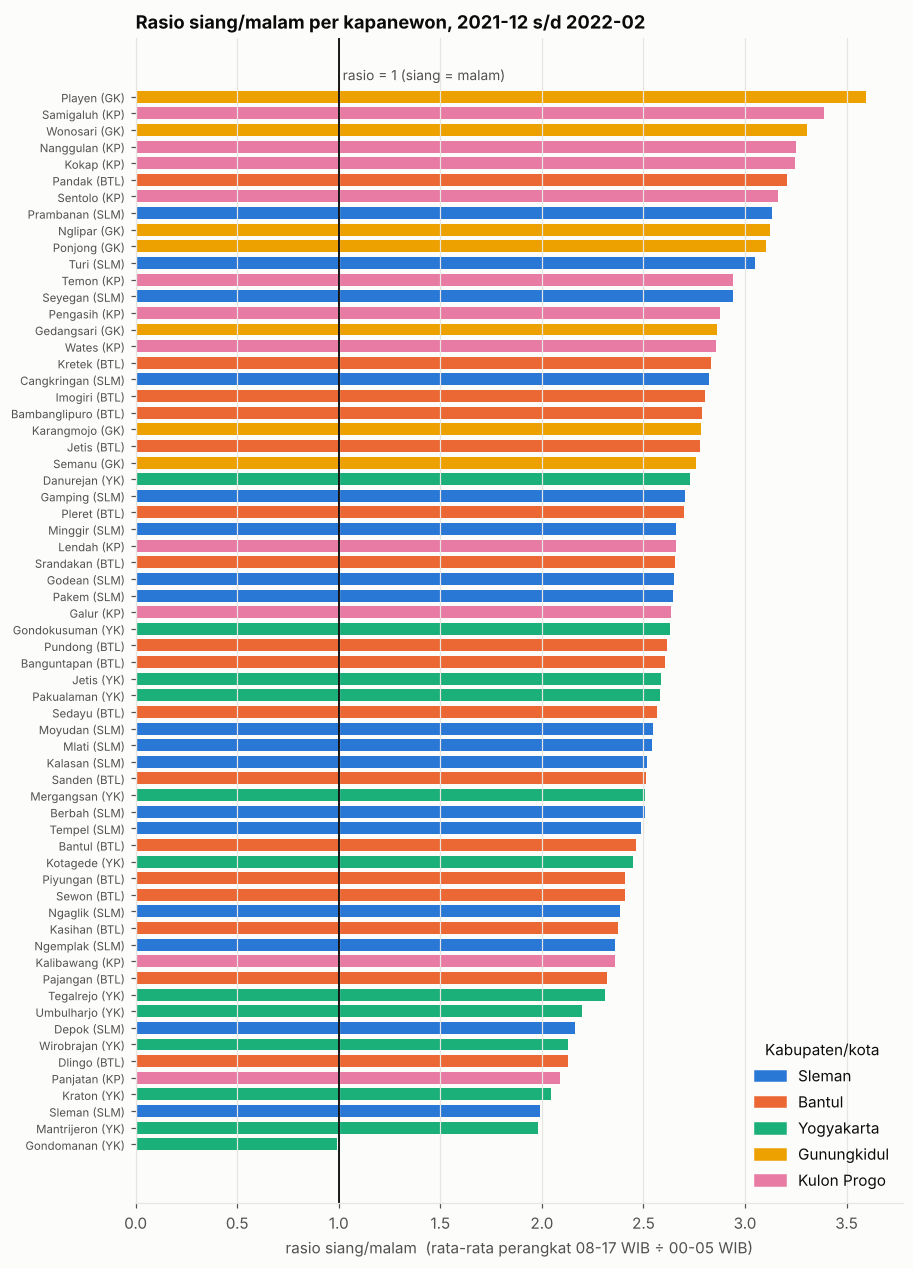

In [ ]:
d = q1_el.sort_values("ratio")
fig, ax = plt.subplots(figsize=(9, 0.19 * len(d) + 1.6))
ax.barh(d.label, d.ratio, color=[KAB_COLORS[k] for k in d.kab_kota], height=0.72)
ax.axvline(1, color=INK, lw=1.2)
ax.text(1.0, len(d) - 0.2, " rasio = 1 (siang = malam)", fontsize=9, color=INK2, va="bottom")
ax.set_xlabel("rasio siang/malam  (rata-rata perangkat 08-17 WIB ÷ 00-05 WIB)")
ax.set_title(f"Rasio siang/malam per kapanewon, {WINDOW_MAIN[0][:7]} s/d {WINDOW_MAIN[1][:7]}")
ax.tick_params(axis="y", labelsize=7.5); ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in KAB_COLORS.values()]
ax.legend(handles, [k.title() for k in KAB_COLORS], loc="lower right", title="Kabupaten/kota")
savefig("02_q1_rasio_siang_malam")

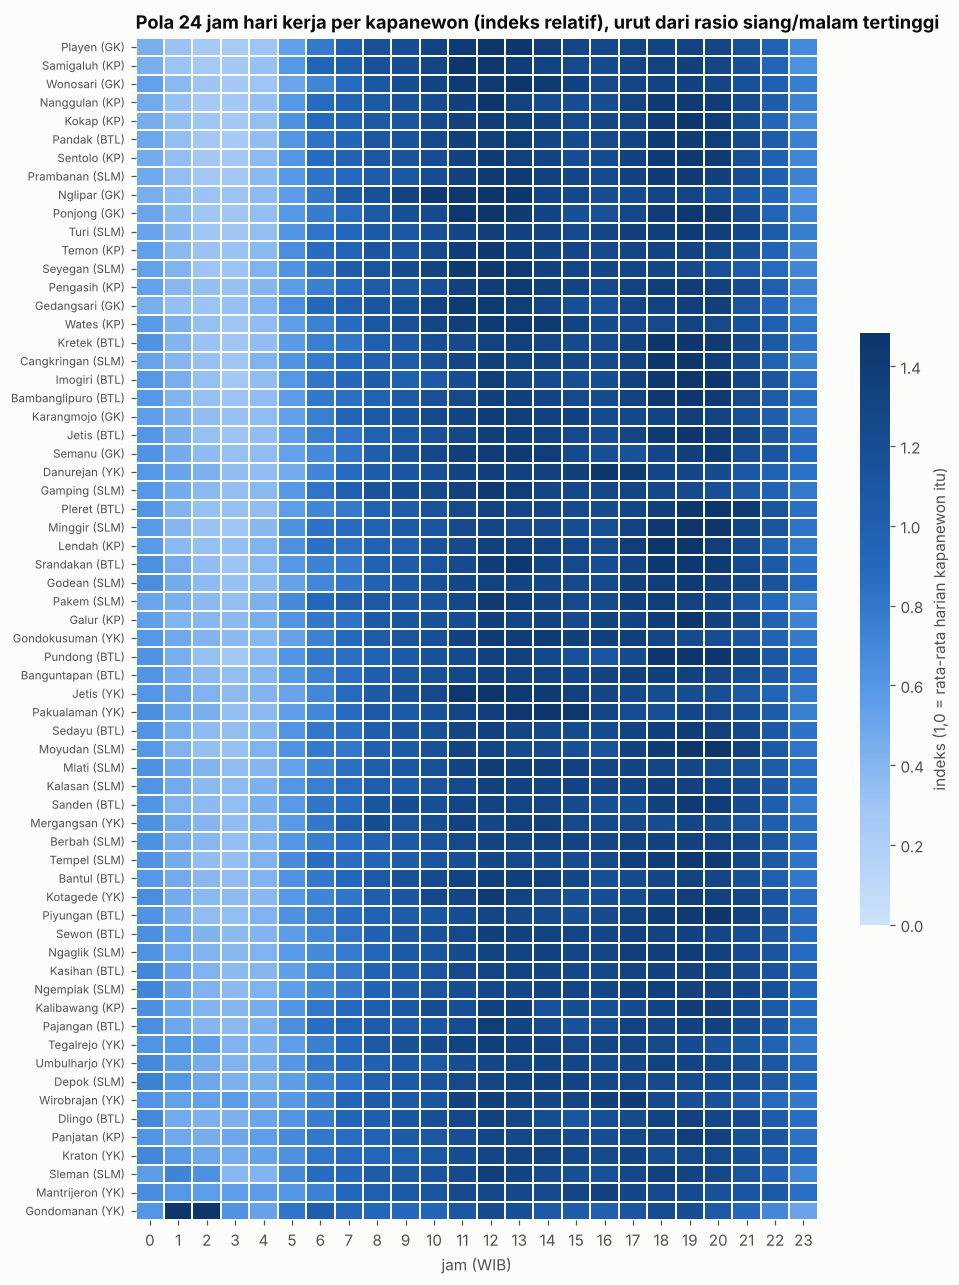

In [ ]:
order_idx = q1_el.sort_values("ratio", ascending=False).index
H = prof_idx.loc[order_idx]
H.index = [label_of[k] for k in H.index]
fig, ax = plt.subplots(figsize=(10, 0.19 * len(H) + 1.8))
sns.heatmap(H, cmap=SEQ, vmin=0, vmax=np.nanpercentile(H.values, 99), ax=ax, linewidths=0.3, linecolor=SURFACE,
            cbar_kws={"label": "indeks (1,0 = rata-rata harian kapanewon itu)", "shrink": 0.5})
ax.set_xlabel("jam (WIB)"); ax.set_ylabel("")
ax.set_title("Pola 24 jam hari kerja per kapanewon (indeks relatif), urut dari rasio siang/malam tertinggi")
ax.tick_params(axis="y", labelsize=7.5); ax.grid(False)
savefig("03_q1_heatmap_pola_24jam")

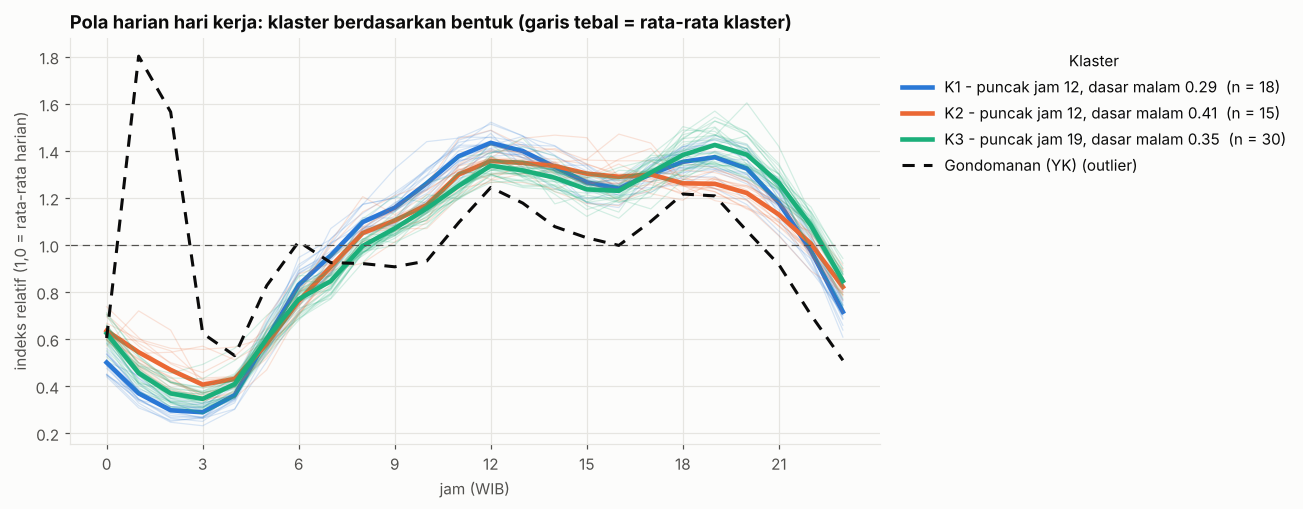

In [ ]:
fig, ax = plt.subplots(figsize=(9.5, 4.8))
for i, c in enumerate(sorted(q1_el.cluster.unique())):
    keys = q1_el.index[q1_el.cluster == c]
    if c.startswith("Outlier"):
        for k in keys: ax.plot(range(24), prof_idx.loc[k].values, color=INK, lw=2, ls=(0, (4, 3)), label=f"{label_of[k]} (outlier)")
        continue
    P = prof_idx.loc[keys]
    for _, row in P.iterrows(): ax.plot(range(24), row.values, color=CAT[i], lw=0.8, alpha=0.18)
    ax.plot(range(24), P.mean().values, color=CAT[i], lw=3, label=f"{c}  (n = {len(keys)})")
ax.axhline(1, color=INK2, lw=0.8, ls=(0, (6, 4)))
ax.set_xticks(range(0, 24, 3)); ax.set_xlabel("jam (WIB)"); ax.set_ylabel("indeks relatif (1,0 = rata-rata harian)")
ax.set_title("Pola harian hari kerja: klaster berdasarkan bentuk (garis tebal = rata-rata klaster)")
ax.legend(title="Klaster", loc="upper left", bbox_to_anchor=(1.01, 1))
savefig("04_q1_klaster_profil")

### 6.2 — Q2: Asal pengunjung Kota Yogyakarta

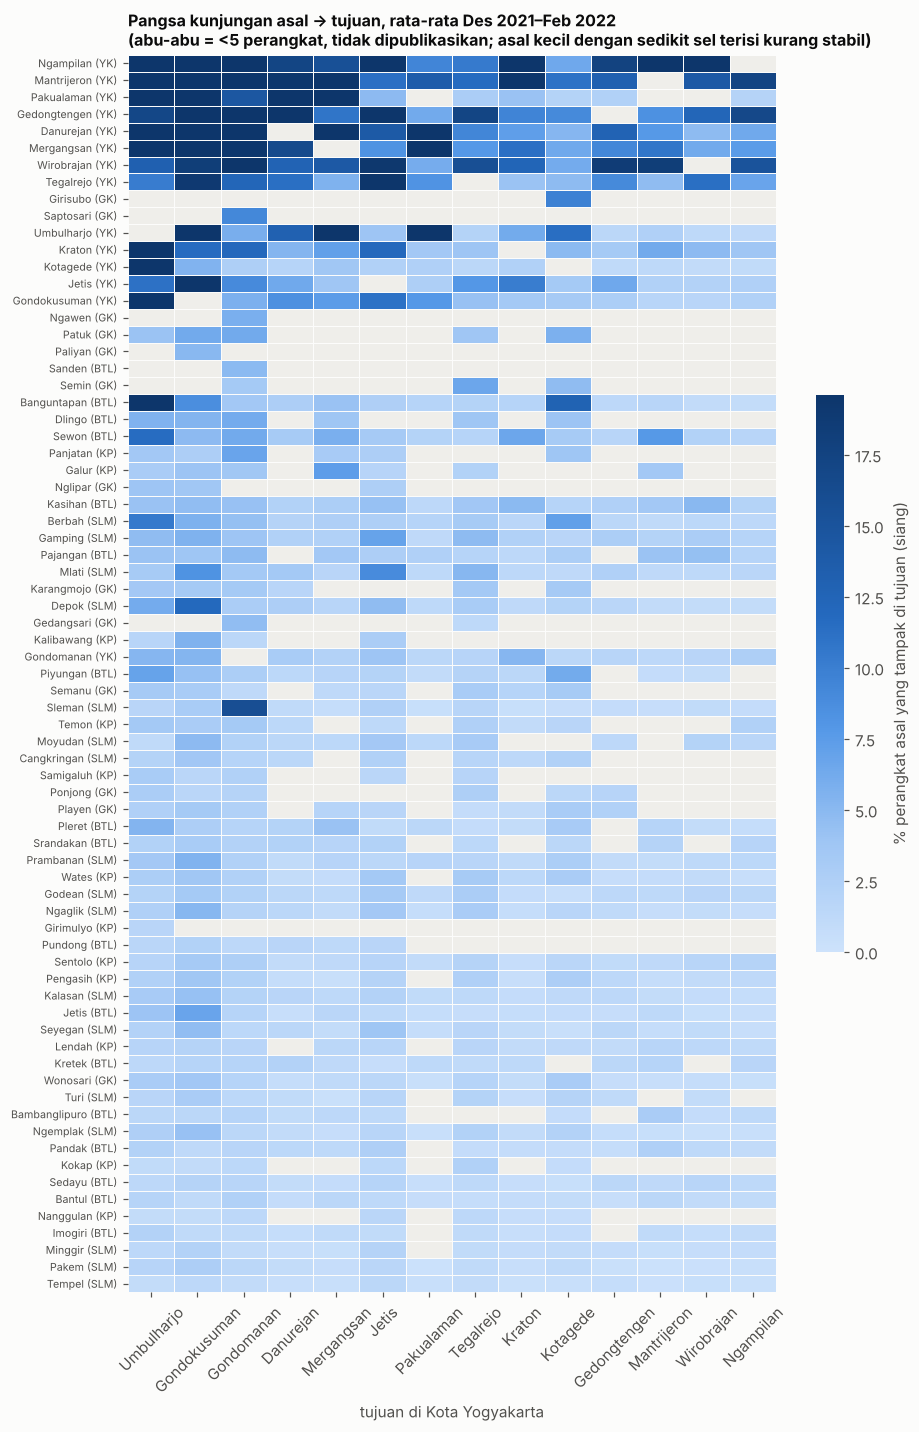

In [ ]:
m = mat.copy()
m.columns = [c.title() for c in m.columns]
m = m.loc[m.mean(axis=1).sort_values(ascending=False).index]
m = m[m.mean().sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(9.5, 0.17 * len(m) + 2.2))
sns.heatmap(m * 100, cmap=SEQ, vmin=0, vmax=np.nanpercentile(m.values * 100, 95), ax=ax, linewidths=0.4, linecolor=SURFACE,
            cbar_kws={"label": "% perangkat asal yang tampak di tujuan (siang)", "shrink": 0.45},
            mask=m.isna())
ax.set_facecolor("#efeeea")           # sel kosong = <5 perangkat, bukan nol
ax.set_xlabel("tujuan di Kota Yogyakarta"); ax.set_ylabel("")
ax.set_title("Pangsa kunjungan asal → tujuan, rata-rata Des 2021–Feb 2022\n(abu-abu = <5 perangkat, tidak dipublikasikan; asal kecil dengan sedikit sel terisi kurang stabil)", fontsize=10.5)
ax.tick_params(axis="y", labelsize=7); ax.tick_params(axis="x", labelrotation=45); ax.grid(False)
savefig("05_q2_matriks_asal_tujuan")

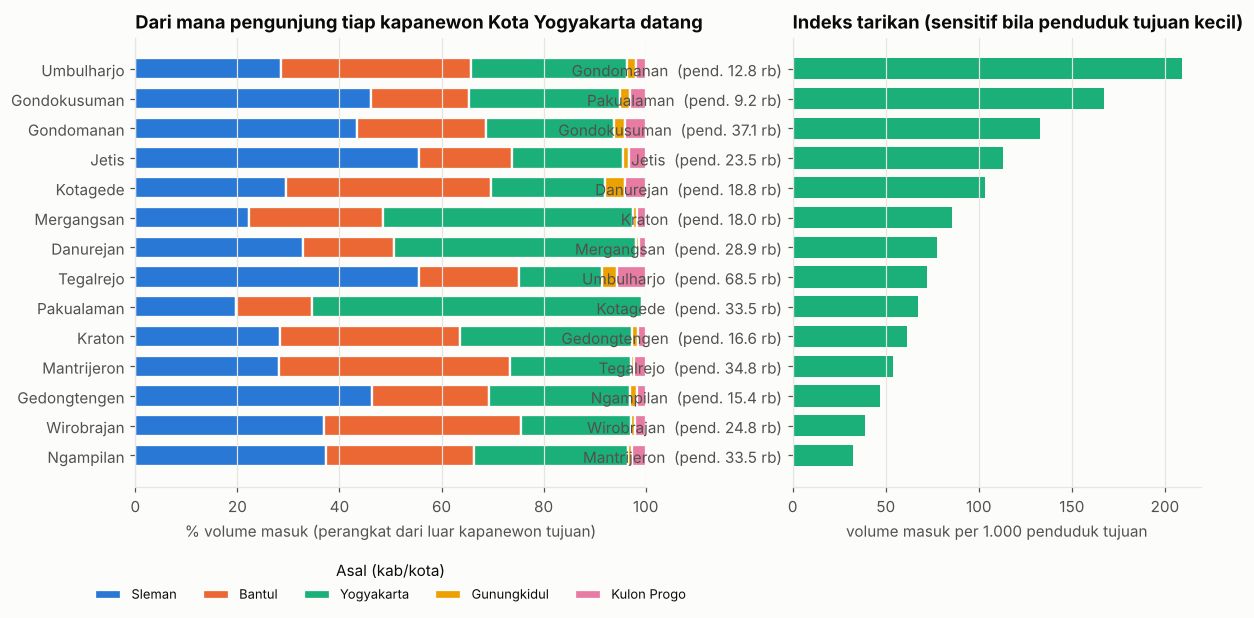

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.3), gridspec_kw={"width_ratios": [1.25, 1], "wspace": 0.32})
ax = axes[0]
left = np.zeros(len(comp_pct))
for kab in KAB_COLORS:
    if kab not in comp_pct.columns: continue
    ax.barh([c.title() for c in comp_pct.index], comp_pct[kab], left=left, color=KAB_COLORS[kab], label=kab.title(),
            edgecolor=SURFACE, linewidth=1.5, height=0.72)
    left += comp_pct[kab].values
ax.set_xlim(0, 100); ax.set_xlabel("% volume masuk (perangkat dari luar kapanewon tujuan)")
ax.set_title("Dari mana pengunjung tiap kapanewon Kota Yogyakarta datang")
ax.legend(title="Asal (kab/kota)", ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.14), fontsize=8.5)
ax.grid(axis="y", visible=False)

ax = axes[1]
t = inflow[inflow.dest_kab_kota == FOCUS_KAB].sort_values("inflow_per_1000")
ax.barh([f"{l.replace(' (YK)', '')}  (pend. {p / 1000:.1f} rb)" for l, p in zip(t.label, t.pop_actual)], t.inflow_per_1000, color=CAT[2], height=0.72)
ax.set_xlabel("volume masuk per 1.000 penduduk tujuan"); ax.set_title("Indeks tarikan (sensitif bila penduduk tujuan kecil)")
ax.grid(axis="y", visible=False)
savefig("06_q2_komposisi_asal_dan_tarikan")

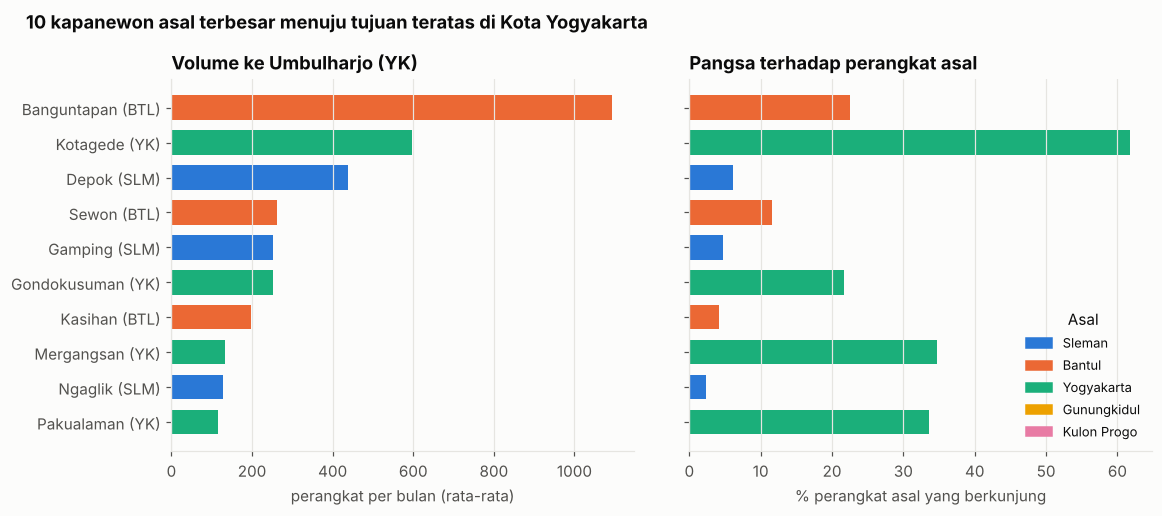

In [ ]:
sub = inter[inter.key_d == top_dest_key]
top_o = (sub.groupby("key_o").agg(vol=("n_maids", "mean"), pangsa=("share", "mean"), kab=("origin_kab_kota", "first"))
         .sort_values("vol", ascending=False).head(10).iloc[::-1])
top_o.index = [label_of[k] for k in top_o.index]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), sharey=True, gridspec_kw={"wspace": 0.12})
axes[0].barh(top_o.index, top_o.vol, color=[KAB_COLORS[k] for k in top_o.kab], height=0.7)
axes[0].set_xlabel("perangkat per bulan (rata-rata)"); axes[0].set_title(f"Volume ke {top_dest_label}")
axes[1].barh(top_o.index, top_o.pangsa * 100, color=[KAB_COLORS[k] for k in top_o.kab], height=0.7)
axes[1].set_xlabel("% perangkat asal yang berkunjung"); axes[1].set_title("Pangsa terhadap perangkat asal")
for a in axes: a.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in KAB_COLORS.values()]
axes[1].legend(handles, [k.title() for k in KAB_COLORS], loc="lower right", fontsize=8.5, title="Asal")
plt.suptitle("10 kapanewon asal terbesar menuju tujuan teratas di Kota Yogyakarta", x=0.01, ha="left", fontweight="bold", y=1.02)
savefig("07_q2_asal_terbesar_tujuan_teratas")

### 6.3 — Q3: Libur akhir tahun vs hari biasa

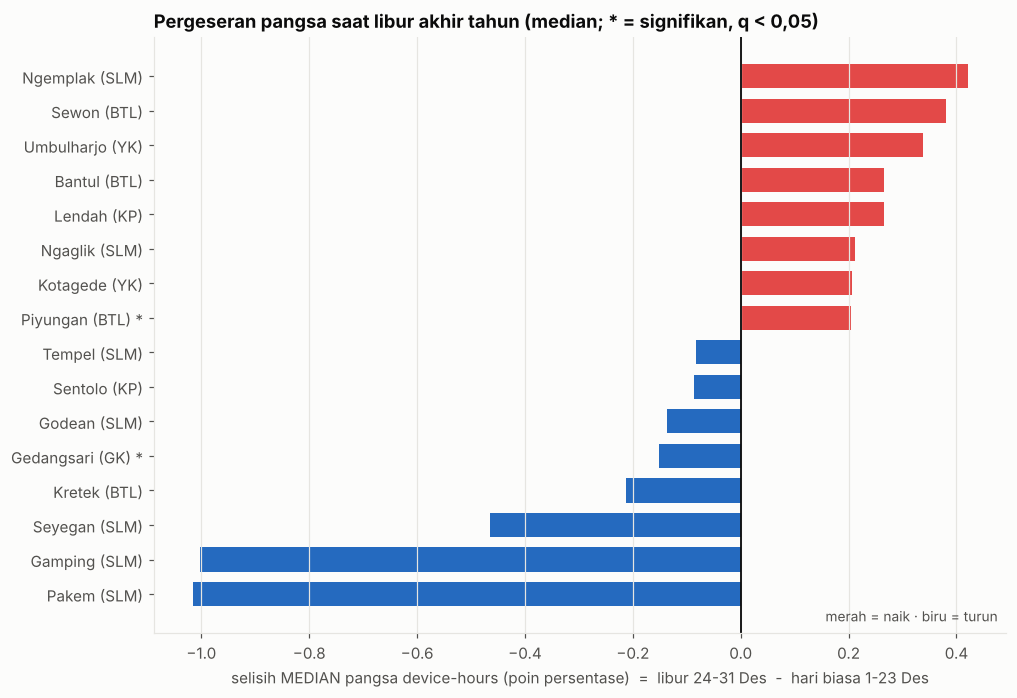

In [ ]:
N = 8
sel = pd.concat([q3.head(N), q3.tail(N)]).drop_duplicates()
sel = sel.sort_values("delta_pp")
cols = [("#e34948" if v > 0 else "#256abf") for v in sel.delta_pp]
lbls = [l + (" *" if q < 0.05 else "") for l, q in zip(sel.label, sel.q_fdr)]
fig, ax = plt.subplots(figsize=(10, 0.34 * len(sel) + 1.6))
ax.barh(lbls, sel.delta_pp, color=cols, height=0.7)
ax.axvline(0, color=INK, lw=1.2)
ax.set_xlabel("selisih MEDIAN pangsa device-hours (poin persentase)  =  libur 24-31 Des  -  hari biasa 1-23 Des")
ax.set_title("Pergeseran pangsa saat libur akhir tahun (median; * = signifikan, q < 0,05)")
ax.grid(axis="y", visible=False)
ax.text(0.99, 0.02, "merah = naik · biru = turun", transform=ax.transAxes, ha="right", color=INK2, fontsize=9)
savefig("08_q3_selisih_pangsa_libur")

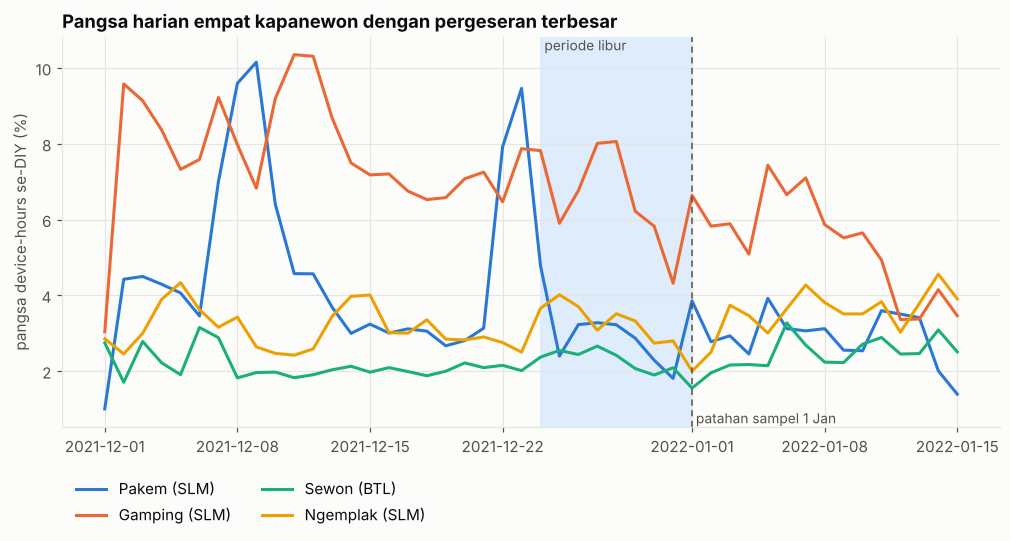

In [ ]:
movers = list(q3.sort_values("delta_pp").index[:2]) + list(q3.sort_values("delta_pp").index[-2:])
fig, ax = plt.subplots(figsize=(11, 4.6))
for i, k in enumerate(movers):
    s = dh_share.loc["2021-12-01":"2022-01-15", k] * 100
    ax.plot(s.index, s.values, color=CAT[i], lw=2, label=label_of[k])
ax.axvspan(pd.Timestamp(HOLIDAY[0]), pd.Timestamp(HOLIDAY[1]) + pd.Timedelta(days=1), color="#cde2fb", alpha=0.6, lw=0)
ax.text(pd.Timestamp(HOLIDAY[0]), ax.get_ylim()[1], " periode libur", va="top", fontsize=9, color=INK2)
ax.axvline(pd.Timestamp("2022-01-01"), color=INK2, lw=1, ls=(0, (4, 3)))
ax.text(pd.Timestamp("2022-01-01"), ax.get_ylim()[0], " patahan sampel 1 Jan", va="bottom", fontsize=9, color=INK2)
ax.set_ylabel("pangsa device-hours se-DIY (%)"); ax.set_title("Pangsa harian empat kapanewon dengan pergeseran terbesar")
ax.legend(ncol=2, loc="upper left", bbox_to_anchor=(0, -0.1))
savefig("09_q3_deret_harian_pergeseran")

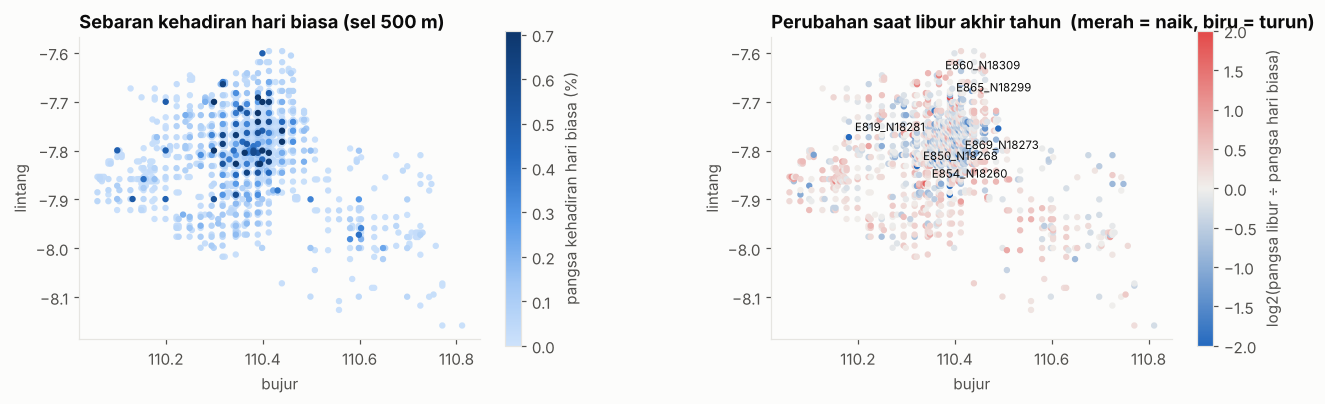

In [ ]:
if USE_CELL:
    fig, axes = plt.subplots(1, 2, figsize=(14, 6.2), gridspec_kw={"wspace": 0.38})
    asp = 1 / np.cos(np.deg2rad(q3c.lat_b.mean()))
    a = axes[0]
    o = q3c.sort_values("mean_share_b")
    sc = a.scatter(o.lon_b, o.lat_b, c=o.mean_share_b * 100, s=10, cmap=SEQ, vmin=0, vmax=np.percentile(o.mean_share_b * 100, 99))
    plt.colorbar(sc, ax=a, shrink=0.6, label="pangsa kehadiran hari biasa (%)")
    a.set_title("Sebaran kehadiran hari biasa (sel 500 m)")
    b = axes[1]
    lim = 2.0
    sc = b.scatter(q3c.lon_b, q3c.lat_b, c=q3c.log2_change.clip(-lim, lim), s=10, cmap=DIV, vmin=-lim, vmax=lim)
    plt.colorbar(sc, ax=b, shrink=0.6, label="log2(pangsa libur ÷ pangsa hari biasa)")
    b.set_title("Perubahan saat libur akhir tahun  (merah = naik, biru = turun)")
    for _, r in pd.concat([q3c.nlargest(3, "log2_change"), q3c.nsmallest(3, "log2_change")]).iterrows():
        b.annotate(r.name, (r.lon_b, r.lat_b), fontsize=7.5, color=INK, xytext=(4, 4), textcoords="offset points")
    for ax_ in axes: ax_.set_aspect(asp); ax_.set_xlabel("bujur"); ax_.set_ylabel("lintang"); ax_.grid(False)
    savefig("10_q3_peta_sel_500m")

### 6.4 — Q4: Validasi dengan Google Mobility

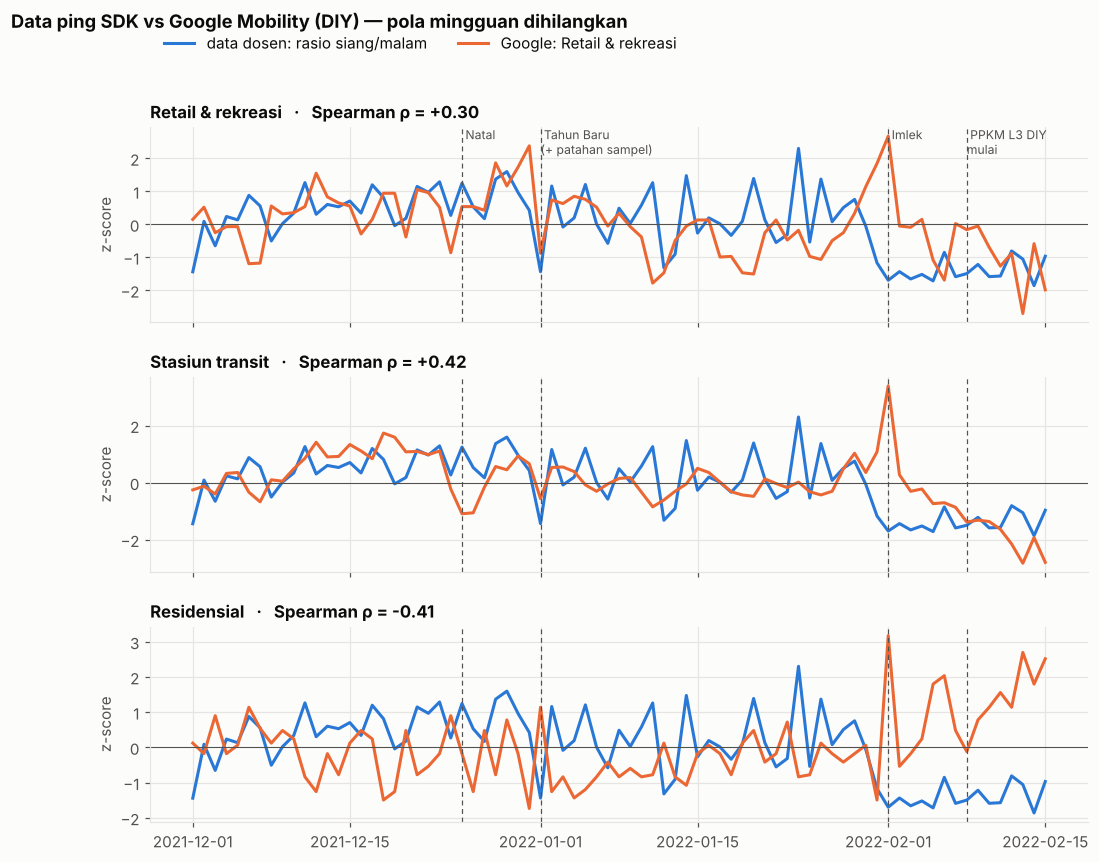

In [ ]:
wname = "Des 2021-15 Feb 2022 (gabungan)"
r = res[wname]; z = (r - r.mean()) / r.std()
cats = [("retail_and_recreation", "Retail & rekreasi"), ("transit_stations", "Stasiun transit"), ("residential", "Residensial")]
fig, axes = plt.subplots(3, 1, figsize=(11, 8.2), sharex=True, gridspec_kw={"hspace": 0.28})
for ax, (c, nm) in zip(axes, cats):
    ax.plot(z.index, z.day_night_ratio, color=CAT[0], lw=2, label="data dosen: rasio siang/malam")
    ax.plot(z.index, z[c], color=CAT[1], lw=2, label=f"Google: {nm}")
    rho = q4[(q4.jendela == wname) & (q4.kategori == c)].rho.iloc[0]
    ax.set_title(f"{nm}   ·   Spearman ρ = {rho:+.2f}", fontsize=11)
    ax.axhline(0, color=INK2, lw=0.7)
    ax.set_ylabel("z-score")
    for d, lbl in EVENTS.items():
        t = pd.Timestamp(d)
        if z.index.min() <= t <= z.index.max():
            ax.axvline(t, color=INK2, lw=0.8, ls=(0, (4, 3)))
            if ax is axes[0]: ax.text(t, ax.get_ylim()[1], " " + lbl, fontsize=8, va="top", color=INK2)
axes[0].legend(loc="upper left", bbox_to_anchor=(0, 1.55), ncol=2)
plt.suptitle("Data ping SDK vs Google Mobility (DIY) — pola mingguan dihilangkan", x=0.01, ha="left", fontweight="bold", y=1.01)
savefig("11_q4_deret_vs_google")

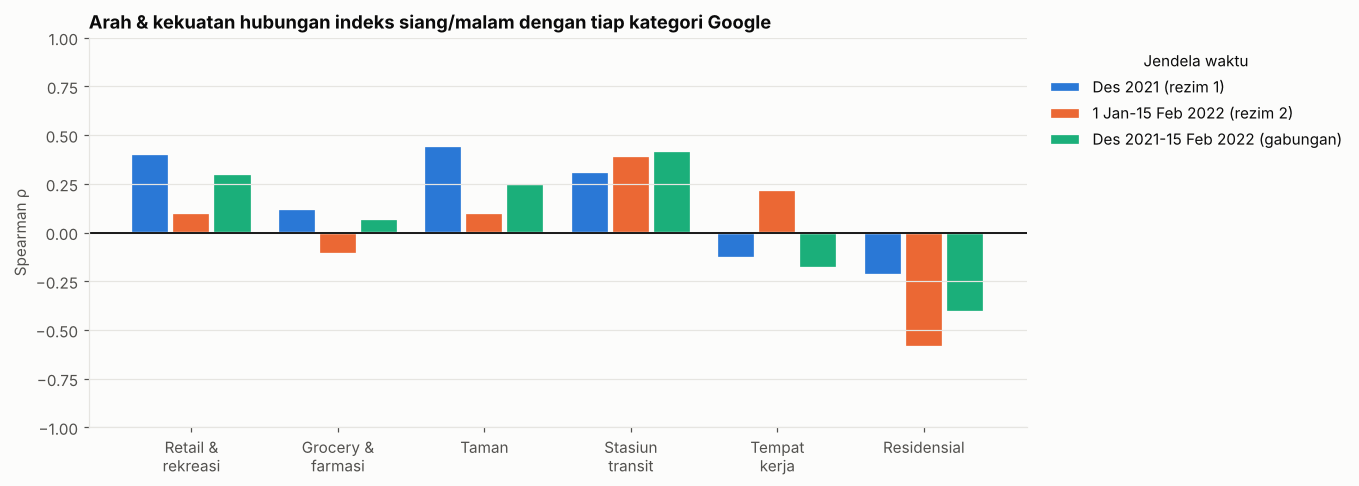

In [ ]:
labels_id = {"retail_and_recreation": "Retail &\nrekreasi", "grocery_and_pharmacy": "Grocery &\nfarmasi", "parks": "Taman",
             "transit_stations": "Stasiun\ntransit", "workplaces": "Tempat\nkerja", "residential": "Residensial"}
fig, ax = plt.subplots(figsize=(11, 4.6))
w = 0.26
for i, wn in enumerate(Q4_WINDOWS):
    vals = q4_wide[wn].values
    ax.bar(np.arange(len(G_COLS)) + (i - 1) * (w + 0.02), vals, width=w, color=CAT[i], label=wn, edgecolor=SURFACE, linewidth=1.5)
ax.axhline(0, color=INK, lw=1.2)
ax.set_xticks(range(len(G_COLS))); ax.set_xticklabels([labels_id[c] for c in G_COLS])
ax.set_ylabel("Spearman ρ"); ax.set_ylim(-1, 1)
ax.set_title("Arah & kekuatan hubungan indeks siang/malam dengan tiap kategori Google")
ax.legend(title="Jendela waktu", loc="upper left", bbox_to_anchor=(1.01, 1)); ax.grid(axis="x", visible=False)
savefig("12_q4_korelasi_per_kategori")

## Tahap 7 — Cek kualitas dan keterbatasan
7.1 reproduksi angka dosen · 7.2 kewajaran terhadap populasi · 7.3 hari anomali · 7.4 penyensoran · 7.5 uji kestabilan.

In [ ]:
# 7.1 Reproduksi night_presence dari data hourly
night_re = hourly[hourly.hour.isin(NIGHT_HOURS)].groupby("key").n_maids.mean()
v = valid[valid.period == "Dec 2021 - Apr 2022"].copy()
v["key"] = v.kab_kota + "|" + v.kapanewon
cmp = v.set_index("key")[["night_presence"]].join(night_re.rename("hitung_ulang"))
cmp["selisih"] = (cmp.night_presence - cmp.hitung_ulang).abs()
print(f"Reproduksi night_presence: selisih maksimum = {cmp.selisih.max():.2e} (n = {len(cmp)}) ->",
      "COCOK" if cmp.selisih.max() < 1e-6 else "PERIKSA")

# 7.2 Kewajaran terhadap populasi (tanpa Gondomanan, sesuai README)
t = meta.set_index("key").join(night_re.rename("night"))
ex = t[t.kapanewon != "GONDOMANAN"]
r_lin = stats.pearsonr(ex.night, ex.pop_actual)[0]
r_log = stats.pearsonr(np.log(ex.night), np.log(ex.pop_actual))[0]
r_log_all = stats.pearsonr(np.log(t.night), np.log(t.pop_actual))[0]
r_home = stats.pearsonr(np.log(t.night), np.log(t.n_users))[0]
print(f"night-presence vs populasi (n={len(ex)}): linear = {r_lin:.2f} | log-log = {r_log:.2f} | log-log + Gondomanan = {r_log_all:.2f} | vs perangkat berumah = {r_home:.2f}  (README: 0,83 / 0,70 / 0,60 / 0,98)")

orig = od_orig.assign(key=od_orig.origin_kab_kota + "|" + od_orig.origin_kapanewon).merge(meta[["key", "pop_actual", "kapanewon"]], on="key")
rows = []
for mth, gdf in orig[~orig.reduced_quality].groupby("month"):
    gdf = gdf[gdf.kapanewon != "GONDOMANAN"]
    rows.append({"bulan": mth, "n": len(gdf), "pearson_linear": stats.pearsonr(gdf.n_homed_maids, gdf.pop_actual)[0],
                 "pearson_loglog": stats.pearsonr(np.log(gdf.n_homed_maids), np.log(gdf.pop_actual))[0]})
print("Perangkat berumah bulanan vs populasi (README Des-Feb: linear 0,82-0,87 | log-log 0,68-0,74):")
display(pd.DataFrame(rows).round(2))

Reproduksi night_presence: selisih maksimum = 2.84e-14 (n = 78) -> COCOK
night-presence vs populasi (n=77): linear = 0.83 | log-log = 0.70 | log-log + Gondomanan = 0.60 | vs perangkat berumah = 0.98  (README: 0,83 / 0,70 / 0,60 / 0,98)
Perangkat berumah bulanan vs populasi (README Des-Feb: linear 0,82-0,87 | log-log 0,68-0,74):


,bulan,n,pearson_linear,pearson_loglog
0,2021-12,77,0.82,0.74
1,2022-01,77,0.87,0.74
2,2022-02,77,0.84,0.68


In [ ]:
# 7.3 Hari anomali: perubahan harian terbesar pada total ping (README: 1 Jan, 16 Feb, 8 Mar 2022)
chg = daily.pings.pct_change().rename("perubahan_harian")
worst = pd.concat([daily.pings.rename("ping"), chg], axis=1).sort_values("perubahan_harian").head(6)
worst["hari"] = worst.index.day_name()
display(worst.round(3))

# 7.4 Penyensoran (privasi k = 5)
display(tier1[["product", "k", "rows_total", "rows_published", "rows_suppressed_pct", "maid_presence_suppressed_pct"]])
display(od_sum)

,ping,perubahan_harian,hari
date,,,
2022-02-16,193179,-0.658,Wednesday
2022-03-08,37757,-0.600,Tuesday
2022-02-20,162397,-0.496,Sunday
2022-03-01,97869,-0.387,Tuesday
2022-04-03,37055,-0.379,Sunday
2022-04-19,41955,-0.369,Tuesday


,product,k,rows_total,rows_published,rows_suppressed_pct,maid_presence_suppressed_pct
0,A_cell500m_daily,5,518176,183548,64.6,6.6
1,B_kapanewon_hourly,5,273979,230418,15.9,0.7


,k,min_nights,od_rows_total,od_rows_published,od_rows_suppressed_pct,inter_zonal_flow_kept_pct,origin_rows_published
0,5,2,19263,9894,48.6,95.3,390


In [ ]:
# 7.5 Uji kestabilan terhadap pilihan definisi
def ratio_in(a, b, el):
    x = hourly[(hourly.date >= a) & (hourly.date <= b)]
    r = x[x.hour.isin(DAY_HOURS)].groupby("key").n_maids.mean() / x[x.hour.isin(NIGHT_HOURS)].groupby("key").n_maids.mean()
    return r.loc[el]
el = q1_el.index
r_dec, r_jf = ratio_in("2021-12-01", "2021-12-31", el), ratio_in("2022-01-01", "2022-02-28", el)
print(f"(a) Q1  Spearman peringkat rasio: Des vs Jan-Feb = {stats.spearmanr(r_dec, r_jf)[0]:.2f}  (n = {len(el)})")

bw = base_idx[base_idx.dayofweek < 5]
alt = (dh_share.loc[hol_idx, q3.index].median() - dh_share.loc[bw, q3.index].median()) * 100
print(f"(b) Q3  Spearman delta_pp (median): baseline semua hari vs hari kerja = {stats.spearmanr(q3.delta_pp, alt.loc[q3.index])[0]:.2f}")

gab = "Des 2021-15 Feb 2022 (gabungan)"
alt_ratio = reg_hour[list(range(9, 17))].sum(axis=1) / reg_hour[list(range(1, 5))].sum(axis=1)   # jam alternatif 09-16 vs 01-04
s2 = deseason(pd.DataFrame({"alt": alt_ratio}).join(g, how="inner").loc[Q4_WINDOWS[gab][0]:Q4_WINDOWS[gab][1]])
for c in ["retail_and_recreation", "transit_stations", "residential"]:
    base_rho = q4[(q4.jendela == gab) & (q4.kategori == c)].rho.iloc[0]
    print(f"(c) Q4  {c:<22} rho utama = {base_rho:+.2f} | rho jam alternatif = {stats.spearmanr(s2.alt, s2[c])[0]:+.2f}")

gm = q1.loc["YOGYAKARTA|GONDOMANAN"]
print(f"(d) Gondomanan: rasio siang/malam = {gm.ratio:.2f}, perangkat berumah / penduduk = {pop.set_index('key').loc['YOGYAKARTA|GONDOMANAN','ratio']:.2f} "
      "(penyebab belum diketahui: bisa perangkat statis/artefak lokasi; jangan ditafsirkan sebagai perilaku)")

(a) Q1  Spearman peringkat rasio: Des vs Jan-Feb = 0.61  (n = 64)
(b) Q3  Spearman delta_pp (median): baseline semua hari vs hari kerja = 0.85
(c) Q4  retail_and_recreation  rho utama = +0.30 | rho jam alternatif = +0.36
(c) Q4  transit_stations       rho utama = +0.42 | rho jam alternatif = +0.44
(c) Q4  residential            rho utama = -0.41 | rho jam alternatif = -0.42
(d) Gondomanan: rasio siang/malam = 0.99, perangkat berumah / penduduk = 2.25 (penyebab belum diketahui: bisa perangkat statis/artefak lokasi; jangan ditafsirkan sebagai perilaku)


### Keterbatasan
1. Komposisi sampel berubah (±87 ribu → ±9 ribu perangkat/hari); kesimpulan kuantitatif dibatasi pada Des 2021 – Feb 2022.
2. Perangkat ≠ orang dan sampel bukan acak; representativitas berbeda antar-wilayah (mis. Gondomanan > 2 perangkat per penduduk).
3. Baris hilang ≠ nol (k = 5); desa paling terdampak, terutama malam hari.
4. Total *device-hours* adalah penyebut pendekatan; `n_maids` secara resmi tidak aditif.
5. OD adalah *visitor count*, bukan jumlah perjalanan; Mar–Apr 2022 berkualitas rendah dan tidak dipakai.
6. Google Mobility hanya level provinsi, persentase dari baseline, dan juga sampel pengguna.
7. Korelasi ≠ sebab-akibat; uji Q3 dan Q4 eksploratif.

## Tahap 8 — Ekspor dan ringkasan temuan

In [ ]:
q1_el.reset_index()[["key", "label", "kab_kota", "day_mean", "night_mean", "ratio", "cov_night", "cluster"]].to_csv(f"{OUT_DIR}/tables/q1_rasio_siang_malam.csv", index=False)
inflow.to_csv(f"{OUT_DIR}/tables/q2_volume_masuk_per_tujuan.csv", index=False)
mat.to_csv(f"{OUT_DIR}/tables/q2_matriks_pangsa_asal_tujuan_kota_yogya.csv")
q3.reset_index().to_csv(f"{OUT_DIR}/tables/q3_pergeseran_pangsa_libur.csv", index=False)
if USE_CELL: q3c.reset_index().to_csv(f"{OUT_DIR}/tables/q3_sel500m_perubahan_libur.csv", index=False)
q4.to_csv(f"{OUT_DIR}/tables/q4_korelasi_google.csv", index=False)
daily.to_csv(f"{OUT_DIR}/tables/harian_indeks_dan_total.csv")

import sklearn, scipy, matplotlib
with open("requirements.txt", "w") as f:
    f.write("\n".join([f"pandas>={pd.__version__.split('.')[0]}", "numpy", f"matplotlib>={matplotlib.__version__.split('.')[0]}",
                        "seaborn", "scipy", "scikit-learn", "notebook"]) + "\n")
print(f"Tersimpan: {len(os.listdir(OUT_DIR + '/figures'))} gambar dan {len(os.listdir(OUT_DIR + '/tables'))} tabel di '{OUT_DIR}/'")

Tersimpan: 12 gambar dan 7 tabel di '/home/claude/work/nb/outputs/'


In [ ]:
# Ringkasan temuan (dihitung otomatis dari hasil di atas)
top3 = q1_el.sort_values("ratio", ascending=False).head(3)
low3 = q1_el.sort_values("ratio").head(3)
comp_top = comp_pct.loc[top_dest_label.split(" (")[0].upper()].sort_values(ascending=False)
up = q3.sort_values("delta_pp", ascending=False).head(3); dn = q3.sort_values("delta_pp").head(3)
rr = q4[q4.jendela == gab].set_index("kategori").rho
fmt = lambda df: "; ".join(f"{r.label} {r.delta_pp:+.2f} pp (q={r.q_fdr:.2f})" for r in df.itertuples())

print("RINGKASAN TEMUAN\n" + "=" * 60)
print("Q1  Rasio siang/malam tertinggi :", "; ".join(f"{r.label} {r.ratio:.2f}" for r in top3.itertuples()))
print("    Rasio terendah              :", "; ".join(f"{r.label} {r.ratio:.2f}" for r in low3.itertuples()))
print(f"    Klaster pola harian         : {q1_el.cluster.value_counts().to_dict()}")
print("Q2  Volume masuk terbesar (DIY) :", "; ".join(f"{r.label} {r.inflow_mean:,.0f}/bln" for r in inflow.head(3).itertuples()))
print(f"    Tujuan teratas di Kota Yogya: {top_dest_label}; asal: " + ", ".join(f"{k.title()} {v:.0f}%" for k, v in comp_top.head(3).items()))
print("Q3  Naik saat libur (median)    :", fmt(up))
print("    Turun saat libur            :", fmt(dn))
print("    Signifikan (q<0,05)         :", ", ".join(f"{r.label} {r.delta_pp:+.2f} pp" for r in q3[q3.q_fdr < 0.05].itertuples()) or "tidak ada")
print("Q4  Spearman (gabungan)         : " + ", ".join(f"{c} {rr[c]:+.2f}" for c in G_COLS))

RINGKASAN TEMUAN
Q1  Rasio siang/malam tertinggi : Playen (GK) 3.60; Samigaluh (KP) 3.39; Wonosari (GK) 3.30
    Rasio terendah              : Gondomanan (YK) 0.99; Mantrijeron (YK) 1.98; Sleman (SLM) 1.99
    Klaster pola harian         : {'K3 - puncak jam 19, dasar malam 0.35': 30, 'K1 - puncak jam 12, dasar malam 0.29': 18, 'K2 - puncak jam 12, dasar malam 0.41': 15, 'Outlier - profil datar': 1}
Q2  Volume masuk terbesar (DIY) : Depok (SLM) 9,176/bln; Banguntapan (BTL) 6,102/bln; Ngaglik (SLM) 5,938/bln
    Tujuan teratas di Kota Yogya: Umbulharjo (YK); asal: Bantul 37%, Yogyakarta 30%, Sleman 29%
Q3  Naik saat libur (median)    : Ngemplak (SLM) +0.42 pp (q=0.52); Sewon (BTL) +0.38 pp (q=0.41); Umbulharjo (YK) +0.34 pp (q=0.55)
    Turun saat libur            : Pakem (SLM) -1.02 pp (q=0.24); Gamping (SLM) -1.00 pp (q=0.30); Seyegan (SLM) -0.46 pp (q=0.17)
    Signifikan (q<0,05)         : Gedangsari (GK) -0.15 pp, Purwosari (GK) +0.03 pp, Piyungan (BTL) +0.20 pp
Q4  Spearman (gabung